# Perform sim

C:\Users\mike\AppData\Local\Temp\ipykernel_5292\1034178156.py:176: RuntimeWarning: divide by zero encountered in log10
  p_t_dB = 10*np.log10(np.abs(a_t)**2)
C:\Users\mike\AppData\Local\Temp\ipykernel_5292\1034178156.py:188: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


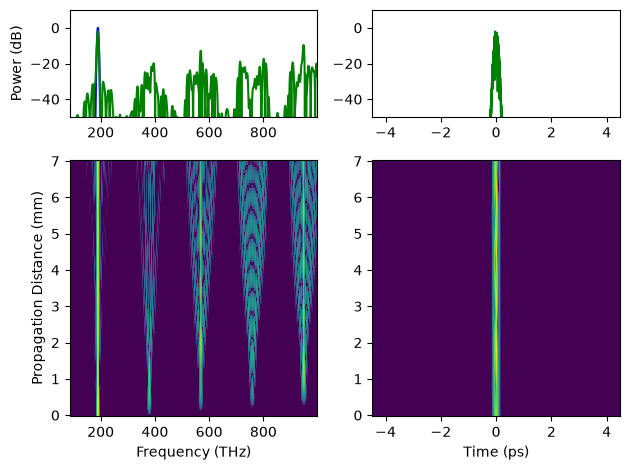

In [8]:
# -*- coding: utf-8 -*-
"""
This example demonstrates supercontinuum generation due to phase-mismatched
second harmonic generation (SHG) in periodically poled lithium niobate (PPLN).
The simulation uses the unidirectional propagation equation (UPE) and is based
on the parameters given for the second example in part III of Conforti et al.
(2010).

References
----------
Conforti M, Baronio F, De Angelis C. Nonlinear envelope equation for broadband
 optical pulses in quadratic media. Physical review. A, Atomic, molecular, and
 optical physics. 2010;81(5).
 https://doi.org/10.1103/PhysRevA.81.053841

"""


# %% Imports
import numpy as np
from scipy.constants import pi, c
from matplotlib import pyplot as plt

import pynlo
from pynlo import utility as ut


# %% Pulse Properties
"""
We first initialize a Gaussian pulse using one of the built-in pulse shapes of
the `Pulse` class. The first few parameters constrain the frequency grid, the
number of points and the frequency range, while the last three set the initial
pulse properties, its center frequency, pulse energy, and pulse width. Since we
are going to be simulating 2nd-order effects, the `alias` parameter has been
increased to support two alias-free Nyquist zones.

"""
n_points = 2**13
v_min = c/3500e-9   # c / 3500 nm
v_max = c/300e-9    # c / 450 nm

v0 = c/1580e-9      # c / 1580 nm
# e_p = 200e-12          
# e_p = 2e-12          
e_p = .2e-12          
t_fwhm = 100e-15     # 50 fs

pulse = pynlo.light.Pulse.Gaussian(n_points, v_min, v_max, v0, e_p, t_fwhm,
                                   alias=2) # anti-aliasing


# %% Mode Properties
"""
In this example we use the refractive index, effective area, and nonlinear
susceptibility to calculate the linear and nonlinear properties of the mode.
The material used in this case is congruent lithium niobate, and we use the
Sellmeier equations from Jundt (1997) for the refractive index. The generalized
2nd-order nonlinear parameter is weighted for second-harmonic generation using
the `g2_shg` function from the `utility.chi2` submodule. Poling is implemented
by indicating the location of each domain inversion. This is calculated using
the `domain_inversion` function of the `utility.chi2` submodule. This example
only uses a constant poling period, but the function also supports the
generation of arbitrarily chirped poling periods.

"""
length = 7e-3 * np.linspace(0,1,1000) # 7 mm
a_eff = 1e-6 * 1e-6 # 15 um * 15 um

#---- Phase Coefficient
def n_cLN(v, T=24.5):
    """
    Refractive index of congruent lithium niobate.

    References
    ----------
    Dieter H. Jundt, "Temperature-dependent Sellmeier equation for the index of
     refraction, ne, in congruent lithium niobate," Opt. Lett. 22, 1553-1555
     (1997). https://doi.org/10.1364/OL.22.001553

    """
    a1 = 5.35583
    a2 = 0.100473
    a3 = 0.20692
    a4 = 100.
    a5 = 11.34927
    a6 = 1.5334e-2
    b1 = 4.629e-7
    b2 = 3.862e-8
    b3 = -0.89e-8
    b4 = 2.657e-5

    wvl = c/v * 1e6 # um
    f = (T-24.5)*(T+570.82)
    n2 = (a1 + b1*f + (a2 + b2*f)/(wvl**2 - (a3 + b3*f)**2)
          + (a4 + b4*f)/(wvl**2 - a5**2) - a6*wvl**2)
    return n2**0.5
# n_eff = n_cLN(pulse.v_grid)
n_eff = 2.5 * np.ones_like(pulse.v_grid)

beta = n_eff * 2*pi*pulse.v_grid/c

#---- 2nd-order nonlinearity
d_eff = 27e-12 # 27 pm / V
chi2_eff = 2 * d_eff
g2 = ut.chi2.g2_shg(v0, pulse.v_grid, n_eff, a_eff, chi2_eff)

# Poling
# p0 = 30e-6 # 30 um poling period
p0=np.linspace(12.5, 2.5, 1000)
z_invs, domains, poled = ut.chi2.domain_inversions(length, 2*pi/p0)

mode = pynlo.medium.Mode(pulse.v_grid, beta, g2=g2, g2_inv=z_invs)


# %% Model
"""
The UPE model is initialized with the pulse and mode objects defined above. At
this stage we also use the target local error to estimate the optimal initial
step size.

"""
model = pynlo.model.UPE(pulse, mode)

#---- Estimate step size
local_error = 1e-6
dz = model.estimate_step_size(local_error=local_error)


# %% Simulate
"""
The model's `simulate` method runs the simulation. We input the total
propagation length, the initial step size, local error, and the number of
simulation steps we wish to record. We receive the output pulse and the
propagations distance, pulse spectrum, and complex envelope at each record
point. To view real-time simulation results (updated whenever the simulation
reaches a record point), set the `plot` keyword to "time", "frq", or "wvl".

"""
pulse_out, z, a_t, a_v = model.simulate(
    length, dz=dz, local_error=local_error, n_records=100, plot=None)


# %% Plot Results
"""
The results are plotted in the time and frequency domains. Although the
3rd-order nonlinearity is not directly included in the propagation model we see
several 3rd-order phenomena due to cascaded 2nd-order effects. Phase-mismatched
SHG yields an effective Kerr effect (see DeSalvo et al. (1992)), which leads to
soliton and dispersive wave generation. Additionally, the high frequency spike
is third-harmonic generation due to cascaded second-harmonic and sum-frequency
generation from the pump frequency. The other spike is due to SHG quasi-phase
matched off of the 3rd-order spatial harmonic of the poling structure.

References
----------
R. DeSalvo, D. J. Hagan, M. Sheik-Bahae, G. Stegeman, E. W. Van Stryland, and
 H. Vanherzeele, "Self-focusing and self-defocusing by cascaded second-order
 effects in KTP," Opt. Lett. 17, 28-30 (1992)

"""
fig = plt.figure("Simulation Results", clear=True)
ax0 = plt.subplot2grid((3,2), (0, 0), rowspan=1)
ax1 = plt.subplot2grid((3,2), (0, 1), rowspan=1)
ax2 = plt.subplot2grid((3,2), (1, 0), rowspan=2, sharex=ax0)
ax3 = plt.subplot2grid((3,2), (1, 1), rowspan=2, sharex=ax1)

p_v_dB = 10*np.log10(np.abs(a_v)**2)
p_v_dB -= p_v_dB.max()
ax0.plot(1e-12*pulse.v_grid, p_v_dB[0], color="b")
ax0.plot(1e-12*pulse.v_grid, p_v_dB[-1], color="g")
ax2.pcolormesh(1e-12*pulse.v_grid, 1e3*z, p_v_dB,
               vmin=-40.0, vmax=0, shading="auto")
ax0.set_ylim(bottom=-50, top=10)
ax2.set_xlabel('Frequency (THz)')

p_t_dB = 10*np.log10(np.abs(a_t)**2)
p_t_dB -= p_t_dB.max()
ax1.plot(1e12*pulse.t_grid, p_t_dB[0], color="b")
ax1.plot(1e12*pulse.t_grid, p_t_dB[-1], color="g")
ax3.pcolormesh(1e12*pulse.t_grid, 1e3*z, p_t_dB,
               vmin=-40.0, vmax=0, shading="auto")
ax1.set_ylim(bottom=-50, top=10)
ax3.set_xlabel('Time (ps)')

ax0.set_ylabel('Power (dB)')
ax2.set_ylabel('Propagation Distance (mm)')
fig.tight_layout()
fig.show()
plt.show()